In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from sklearn.cluster import KMeans
import os

HO_TEN = "TRẦN THỊ MỸ DUNG"
MSSV = "6451071008"

def thong_tin(buoc):
    print(f"Họ tên: {HO_TEN}")
    print(f"MSSV: {MSSV}")
    print(f"BÀI 6 - {buoc}")
    print("-" * 50)

print("Import thư viện thành công!")


Import thư viện thành công!


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 1
--------------------------------------------------


Saving download.jpg to download.jpg
Tên ảnh: download.jpg
Kích thước ảnh: (900, 450)


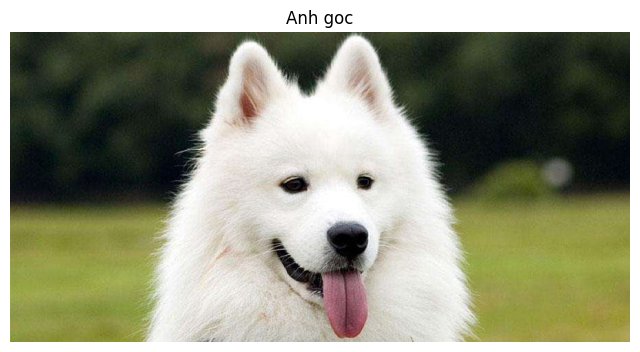

In [2]:

# Bước 1: Upload và hiển thị ảnh gốc
thong_tin("Buoc 1")

uploaded = files.upload()
file_name = next(iter(uploaded))

img = Image.open(file_name).convert("RGB")

print("Tên ảnh:", file_name)
print("Kích thước ảnh:", img.size)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Anh goc")
plt.axis("off")
plt.show()


In [3]:

# Bước 2: Chuyển ảnh thành mảng số và lấy kích thước
thong_tin("Buoc 2")

img_array = np.array(img)

height, width, channels = img_array.shape

print("Chiều cao:", height)
print("Chiều rộng:", width)
print("Số kênh màu:", channels)
print("Kích thước mảng:", img_array.shape)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 2
--------------------------------------------------
Chiều cao: 450
Chiều rộng: 900
Số kênh màu: 3
Kích thước mảng: (450, 900, 3)


In [4]:

# Bước 3: Chuẩn hóa màu và chuyển ảnh từ 3D sang 2D
thong_tin("Buoc 3")

img_normalized = img_array.astype("float32") / 255.0

pixels = img_normalized.reshape(-1, 3)

print("Kích thước ảnh ban đầu:", img_array.shape)
print("Kích thước sau chuyển đổi:", pixels.shape)
print("Giá trị nhỏ nhất:", pixels.min())
print("Giá trị lớn nhất:", pixels.max())


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 3
--------------------------------------------------
Kích thước ảnh ban đầu: (450, 900, 3)
Kích thước sau chuyển đổi: (405000, 3)
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 1.0


In [5]:

# Bước 4: Gom cụm màu ảnh bằng K-Means với 32 màu
thong_tin("Buoc 4")

k = 32

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=3,
    max_iter=100
)

labels = kmeans.fit_predict(pixels)

colors = kmeans.cluster_centers_

compressed_pixels = colors[labels]

print("Số màu yêu cầu:", k)
print("Số tâm màu:", len(colors))
print("Kích thước dữ liệu sau gom cụm:", compressed_pixels.shape)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 4
--------------------------------------------------
Số màu yêu cầu: 32
Số tâm màu: 32
Kích thước dữ liệu sau gom cụm: (405000, 3)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 5
--------------------------------------------------
Kích thước ảnh sau khôi phục: (450, 900, 3)


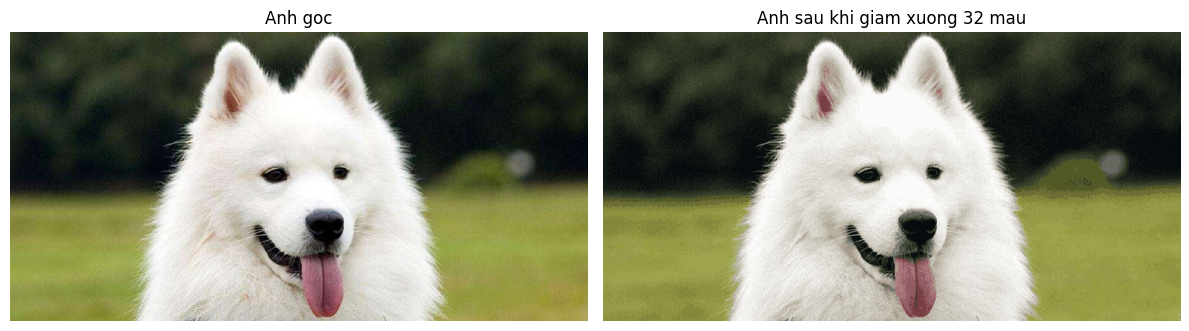

In [6]:

# Bước 5: Khôi phục ảnh và so sánh với ảnh gốc
thong_tin("Buoc 5")

compressed_image = compressed_pixels.reshape(
    height, width, 3
)

compressed_image = np.clip(
    compressed_image * 255,
    0, 255
).astype("uint8")

print("Kích thước ảnh sau khôi phục:", compressed_image.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed_image)
plt.title("Anh sau khi giam xuong 32 mau")
plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:

# Bước 6: Lưu ảnh giảm màu và so sánh kích thước file
thong_tin("Buoc 6")

output_file = "6451071008_Bai6_KMeans_32mau.png"

result_image = Image.fromarray(compressed_image)
result_image.save(output_file)

original_size = os.path.getsize(file_name) / 1024
compressed_size = os.path.getsize(output_file) / 1024

print("File ảnh gốc:", file_name)
print(f"Kích thước ảnh gốc: {original_size:.2f} KB")

print("\nFile kết quả:", output_file)
print(f"Kích thước ảnh kết quả: {compressed_size:.2f} KB")

if original_size > 0:
    reduction = (1 - compressed_size / original_size) * 100
    print(f"Thay đổi dung lượng: {reduction:.2f}%")

files.download(output_file)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 6 - Buoc 6
--------------------------------------------------
File ảnh gốc: download.jpg
Kích thước ảnh gốc: 40.14 KB

File kết quả: 6451071008_Bai6_KMeans_32mau.png
Kích thước ảnh kết quả: 162.29 KB
Thay đổi dung lượng: -304.26%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>